# Gradientes estocásticos
## Gustavo Barboza Blanco

In [2]:
import numpy as np
import matplotlib.pyplot as plt

Función de prueba:
$$
f(\theta_x,\theta_y) = \theta_x ^2 + \theta_y ^6
$$

In [3]:
def thetaFunction(x_vals,y_vals):
    return x_vals**2 + y_vals**6

In [4]:
#Dado que esta funcion es completamente separable, calculo ambas componentes por separado
def function_gradX(x_vals):
    return 2*x_vals
def function_gradY(y_vals):
    return 6*y_vals**5

### 1. Gradiente regular:

El algoritmo es tal que: 
$$
\theta_{t + 1} = \theta_{t} - \alpha \nabla_{\theta} f
$$

In [5]:
def regularMethod_Minimization(function,function_gradX,function_gradY,alpha,x_0,y_0,time_span):
    x_component = np.zeros(len(time_span))
    y_component = np.zeros(len(time_span))

    x_component[0] = x_0
    y_component[0] = y_0
    
    for t in range(1,len(time_span)):
        x_component[t] = x_component[t-1] - alpha*function_gradX(x_component[t-1])
        y_component[t] = y_component[t-1] - alpha*function_gradY(y_component[t-1])
    return x_component,y_component

In [6]:
#Implementación
time_span = np.array([1,2,3,4,5,6,7,8,9,10])
alphas = np.array([0.7, 0.5, 0.3, 0.1])
x0 = 1
y0 = 1
colors_alpha = ['purple', 'blue', 'orange', 'green']

/tmp/ipykernel_70627/1497735547.py:5: RuntimeWarning: overflow encountered in scalar power
  return 6*y_vals**5
/tmp/ipykernel_70627/1275350233.py:10: RuntimeWarning: invalid value encountered in scalar subtract
  y_component[t] = y_component[t-1] - alpha*function_gradY(y_component[t-1])


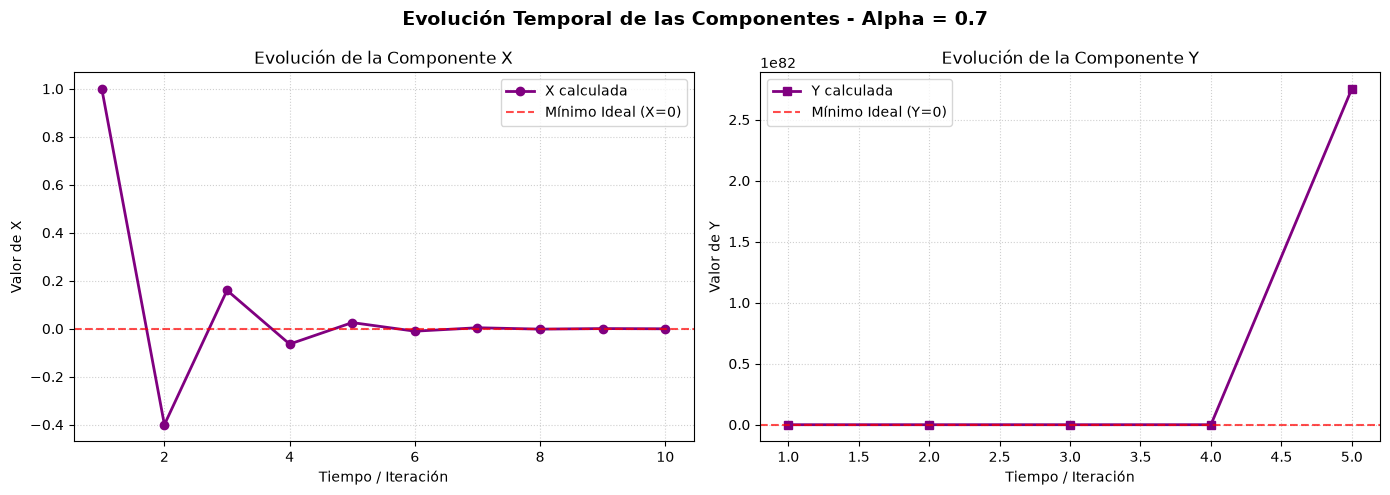

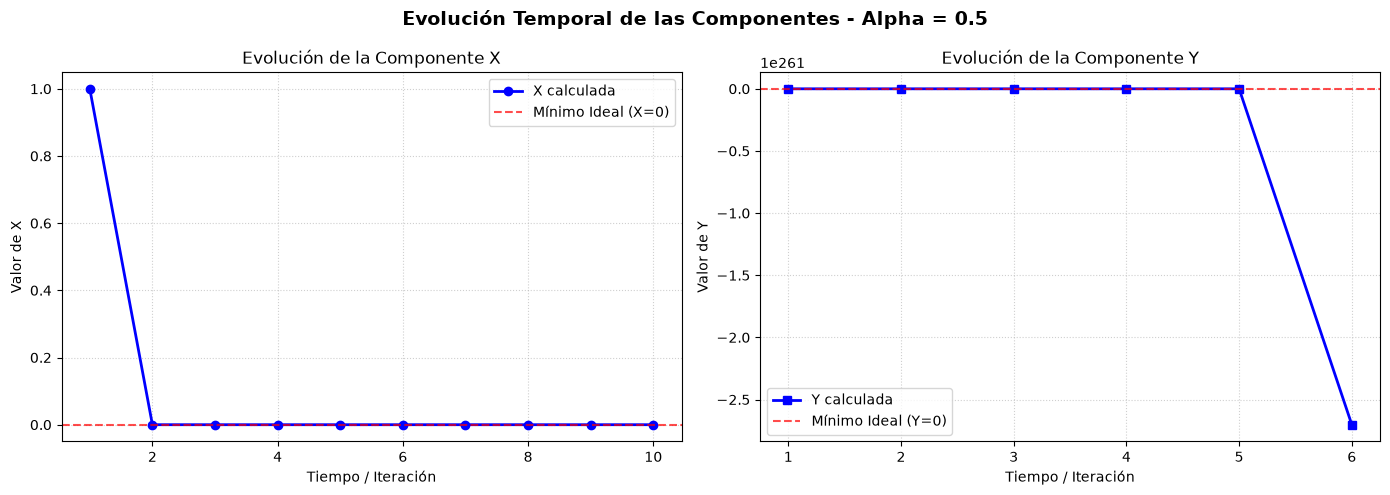

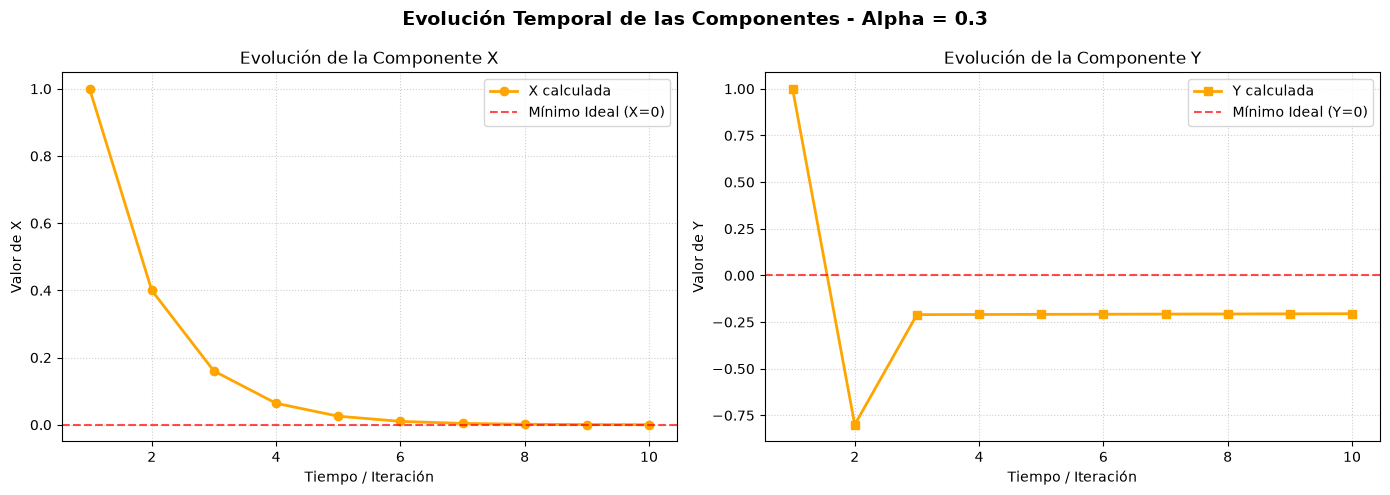

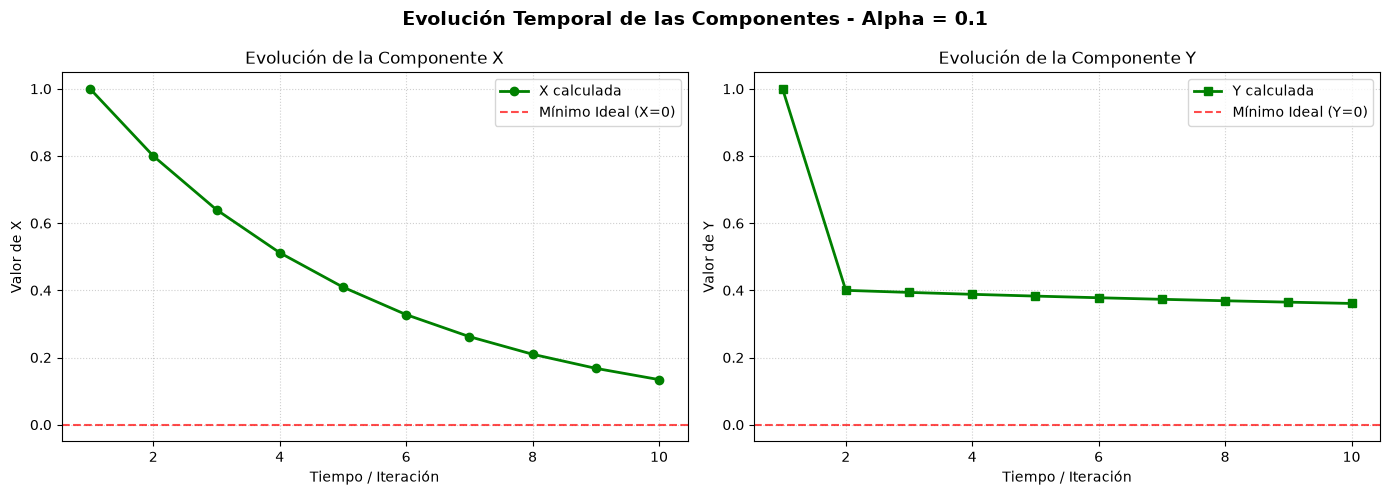

In [7]:
#NOTA: El código de esta celda fue generado usando la IA de google,
#Le pedí que usara mi implementación del algoritmo y generara las gráficas correspondientes
for alpha, color in zip(alphas, colors_alpha):
    # Ejecutar el algoritmo
    x_res, y_res = regularMethod_Minimization(thetaFunction, function_gradX, function_gradY, alpha, x0, y0, time_span)
    
    # Crear una figura independiente para cada Alpha con 2 subgráficas
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(f'Evolución Temporal de las Componentes - Alpha = {alpha}', fontsize=14, fontweight='bold')
    
    # Gráfica de la Izquierda: Componente X en función del tiempo
    ax1.plot(time_span, x_res, marker='o', color=color, linestyle='-', linewidth=2, label=f'X calculada')
    ax1.axhline(0, color='red', linestyle='--', alpha=0.7, label='Mínimo Ideal (X=0)')
    ax1.set_title('Evolución de la Componente X')
    ax1.set_xlabel('Tiempo / Iteración')
    ax1.set_ylabel('Valor de X')
    ax1.grid(True, linestyle=':', alpha=0.6)
    ax1.legend()
    
    # Gráfica de la Derecha: Componente Y en función del tiempo
    ax2.plot(time_span, y_res, marker='s', color=color, linestyle='-', linewidth=2, label=f'Y calculada')
    ax2.axhline(0, color='red', linestyle='--', alpha=0.7, label='Mínimo Ideal (Y=0)')
    ax2.set_title('Evolución de la Componente Y')
    ax2.set_xlabel('Tiempo / Iteración')
    ax2.set_ylabel('Valor de Y')
    ax2.grid(True, linestyle=':', alpha=0.6)
    
    # NOTA: Activamos escala logarítmica solo en Y si los valores explotan hacia el infinito
    # para que la gráfica siga siendo legible y no se deforme.
    if np.max(np.abs(y_res)) > 100:
        ax2.set_yscale('symlog') # 'symlog' permite graficar valores enormes positivos y negativos
        ax2.set_ylabel('Valor de Y (Escala Simétrica Logarítmica)')
        
    ax2.legend()
    
    plt.tight_layout()
plt.show()

### 2.Método de momentum:

El algoritmo es:
$$
\theta_{t + 1} = \theta_{t} - \alpha P_{t+1}
$$
Donde:
$$
P_{t+1} = \beta P_{t} + (1-\beta)\nabla f_{\theta}
$$

In [8]:
def momentumMethod(function,function_gradX,function_gradY,alpha,beta,x_0,y_0,px_0,py_0,time_span):
    x_component = np.zeros(len(time_span))
    y_component = np.zeros(len(time_span))
    px_component = np.zeros(len(time_span))
    py_component = np.zeros(len(time_span))

    x_component[0] = x_0
    y_component[0] = y_0
    px_component[0] = px_0
    py_component[0] = py_0
    
    for t in range(1,len(time_span)):
        px_component[t] = beta*px_component[t-1] + (1-beta)*function_gradX(x_component[t-1])
        py_component[t] = beta*py_component[t-1] + (1-beta)*function_gradY(y_component[t-1])
        x_component[t] = x_component[t-1] - alpha*px_component[t]
        y_component[t] = y_component[t-1] - alpha*py_component[t]
    return x_component,y_component,px_component,py_component

In [9]:
#Implementación 
time_span = np.linspace(1, 100, 100, dtype=int)
x0,y0,px0,py0 = 1,1,0,0
betas = np.array([0.9,0.99])

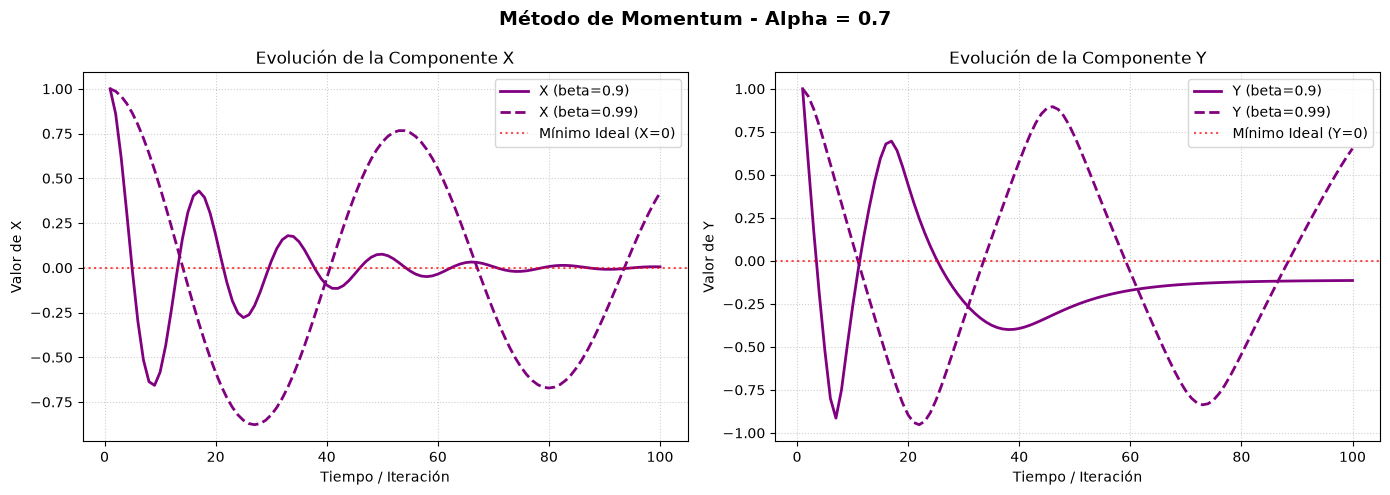

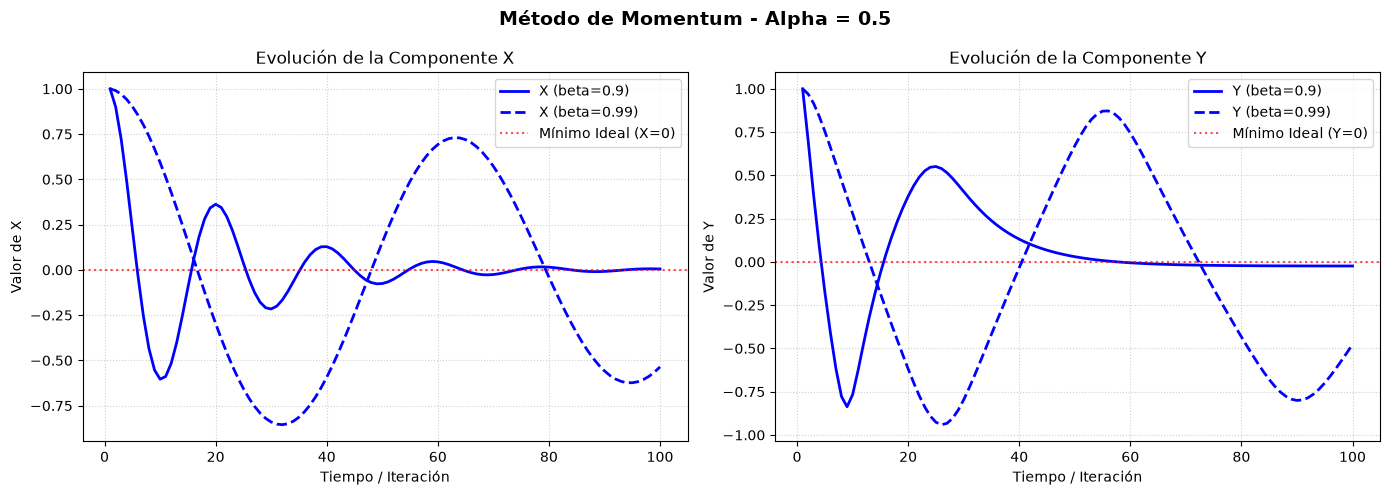

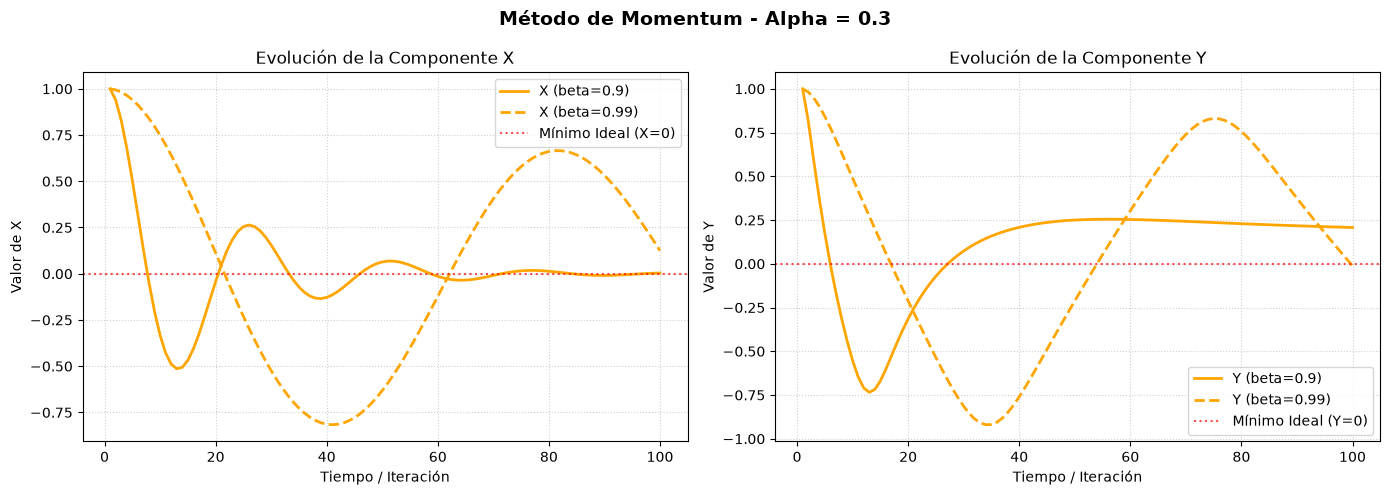

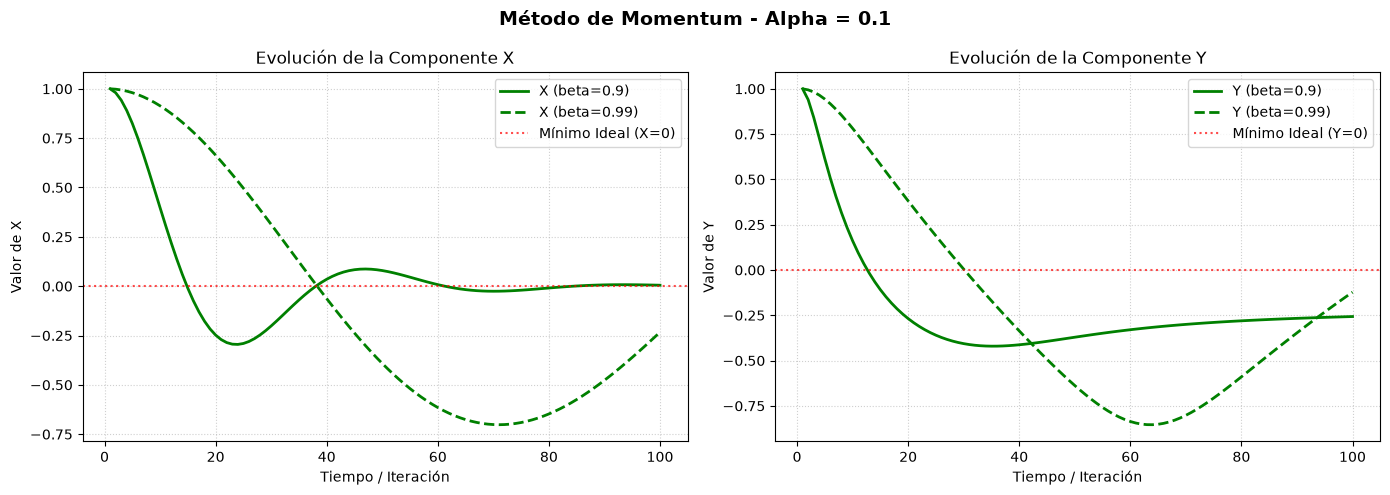

In [10]:
#NOTA: estas gráficas se las solicité a la IA Claude
linestyles_beta = ['-', '--']
# Graficamos las 8 combinaciones (4 alphas x 2 betas)
for alpha, color in zip(alphas, colors_alpha):
    # Una figura por Alpha, con las 2 betas superpuestas en cada subgráfica
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(f'Método de Momentum - Alpha = {alpha}', fontsize=14, fontweight='bold')

    for beta, ls in zip(betas, linestyles_beta):
        x_res, y_res, px_res, py_res = momentumMethod(
            thetaFunction, function_gradX, function_gradY,
            alpha, beta, x0, y0, px0, py0, time_span
        )

        ax1.plot(time_span, x_res, linestyle=ls, color=color, linewidth=2,
                 label=f'X (beta={beta})')
        ax2.plot(time_span, y_res, linestyle=ls, color=color, linewidth=2,
                 label=f'Y (beta={beta})')

    ax1.axhline(0, color='red', linestyle=':', alpha=0.7, label='Mínimo Ideal (X=0)')
    ax1.set_title('Evolución de la Componente X')
    ax1.set_xlabel('Tiempo / Iteración')
    ax1.set_ylabel('Valor de X')
    ax1.grid(True, linestyle=':', alpha=0.6)
    ax1.legend()

    ax2.axhline(0, color='red', linestyle=':', alpha=0.7, label='Mínimo Ideal (Y=0)')
    ax2.set_title('Evolución de la Componente Y')
    ax2.set_xlabel('Tiempo / Iteración')
    ax2.set_ylabel('Valor de Y')
    ax2.grid(True, linestyle=':', alpha=0.6)

    # Escala logarítmica simétrica si los valores de Y explotan
    max_abs_y = np.max(np.abs([momentumMethod(thetaFunction, function_gradX, function_gradY,
                                               alpha, b, x0, y0, px0, py0, time_span)[1]
                                for b in betas]))
    if max_abs_y > 100:
        ax2.set_yscale('symlog')
        ax2.set_ylabel('Valor de Y (Escala Simétrica Logarítmica)')

    ax2.legend()
    plt.tight_layout()

plt.show()

Ahora para las componentes de momentum:

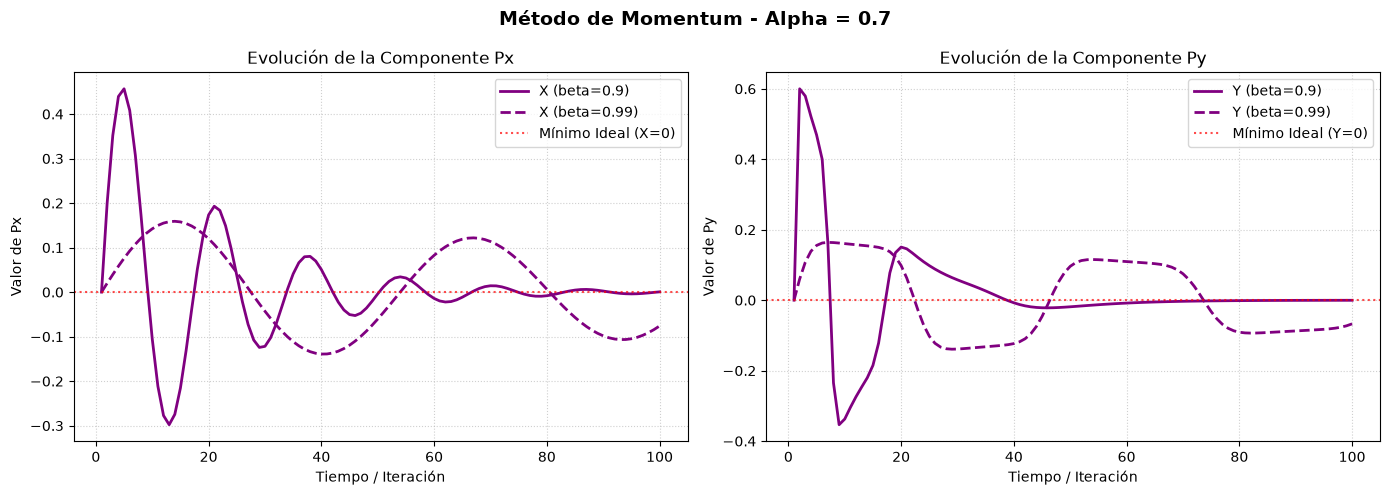

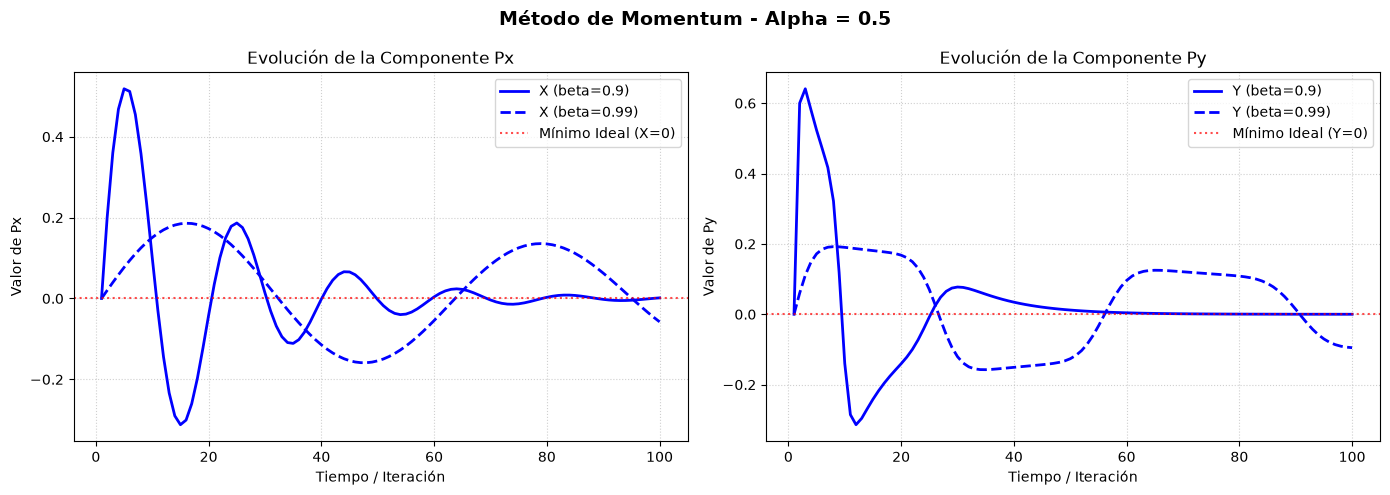

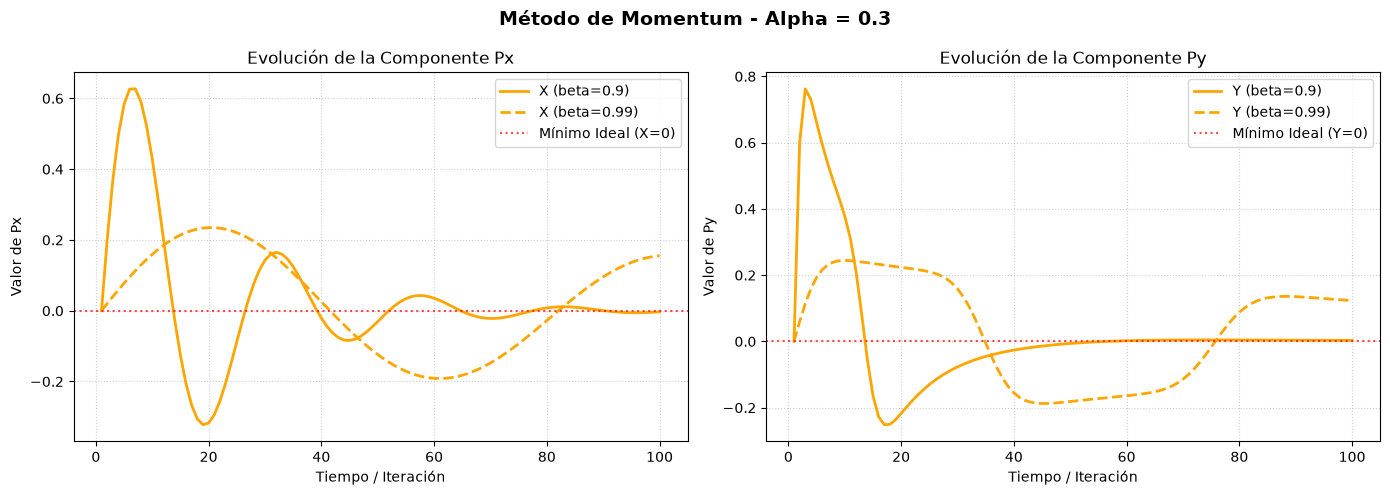

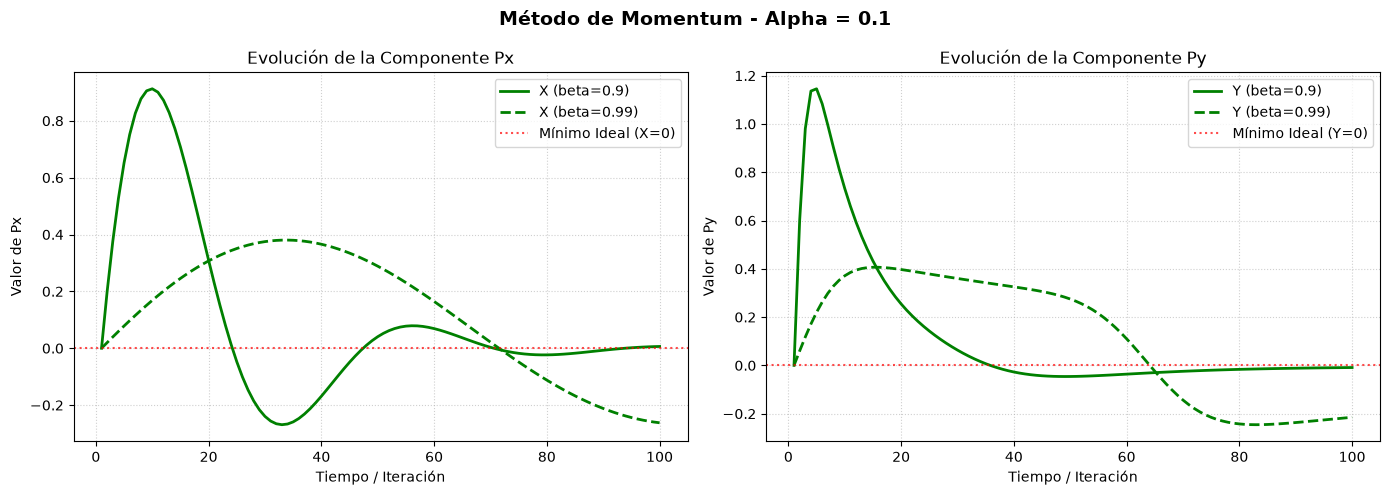

In [11]:
for alpha, color in zip(alphas, colors_alpha):
    # Una figura por Alpha, con las 2 betas superpuestas en cada subgráfica
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(f'Método de Momentum - Alpha = {alpha}', fontsize=14, fontweight='bold')

    for beta, ls in zip(betas, linestyles_beta):
        x_res, y_res, px_res, py_res = momentumMethod(
            thetaFunction, function_gradX, function_gradY,
            alpha, beta, x0, y0, px0, py0, time_span
        )

        ax1.plot(time_span, px_res, linestyle=ls, color=color, linewidth=2,
                 label=f'X (beta={beta})')
        ax2.plot(time_span, py_res, linestyle=ls, color=color, linewidth=2,
                 label=f'Y (beta={beta})')

    ax1.axhline(0, color='red', linestyle=':', alpha=0.7, label='Mínimo Ideal (X=0)')
    ax1.set_title('Evolución de la Componente Px')
    ax1.set_xlabel('Tiempo / Iteración')
    ax1.set_ylabel('Valor de Px')
    ax1.grid(True, linestyle=':', alpha=0.6)
    ax1.legend()

    ax2.axhline(0, color='red', linestyle=':', alpha=0.7, label='Mínimo Ideal (Y=0)')
    ax2.set_title('Evolución de la Componente Py')
    ax2.set_xlabel('Tiempo / Iteración')
    ax2.set_ylabel('Valor de Py')
    ax2.grid(True, linestyle=':', alpha=0.6)

    # Escala logarítmica simétrica si los valores de Y explotan
    max_abs_y = np.max(np.abs([momentumMethod(thetaFunction, function_gradX, function_gradY,
                                               alpha, b, x0, y0, px0, py0, time_span)[1]
                                for b in betas]))
    if max_abs_y > 100:
        ax2.set_yscale('symlog')
        ax2.set_ylabel('Valor de Y (Escala Simétrica Logarítmica)')

    ax2.legend()
    plt.tight_layout()

plt.show()